# 8. Численная проверка модели Паскуази

Правильно ли решатель передает фазу полей, связь резонаторов и динамику боковых супермод? Сначала проверим оба поля на точном решении, затем сравним эволюцию гауссова импульса с независимым интегрированием системы. В конце посмотрим, как меняется импульс при включении боковых супермод.

Модель задают уравнения (S16)-(S17). Координата `x` имеет период 1, время измеряется в оборотах усиливающей петли. При `N=0` остаются кольцо и одна супермода петли, при `N=5` у петли 11 супермод. [Bao et al., Laser cavity-soliton microcombs](https://doi.org/10.1038/s41566-019-0379-5).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy.integrate import solve_ivp

from lle.config import load_config
from lle.numerics.grid import PeriodicGrid
from lle.numerics.pasquazi import solve
from lle.physics.pasquazi import PasquaziParameters
from lle.runs.project import get_experiment_dir
from lle.workflows.pasquazi.config import PasquaziConfig
from lle.workflows.pasquazi.workflow import simulate

results = get_experiment_dir(8) / "results"
results.mkdir(exist_ok=True)

## 1. Точное вращающееся поле

При `kappa=1`, `gain=1/2` и `2*pi*detuning=3/4` подстановка пространственно однородных полей дает решение `a(t)=sqrt(3/4)*exp(i*t/4)`, `b_0(t)=(1+i)*a(t)`. Интенсивности постоянны, тогда как комплексная фаза меняется. Измеряем максимальную абсолютную ошибку каждого поля по всем узлам и всем сохраненным моментам до `t=1`. Порядок по времени оцениваем как `log2(E(dt)/E(dt/2))`.

In [2]:
grid = PeriodicGrid(16, 1)
p = PasquaziParameters(kappa=1, gain=0.5, detuning=0.75/(2*np.pi))
initial = np.sqrt(0.75) * np.ones((2, grid.num_points), dtype=complex)
initial[1] *= 1 + 1j
previous = None
print("      dt       max |a-a*|    max |b-b*|    порядок a    порядок b")
for dt in (0.02, 0.01, 0.005, 0.0025):
    sol = solve(p, grid, initial, time_step=dt, time_end=1, recording_interval=0.1)
    exact = np.exp(0.25j * sol.ring.times[:, None]) * initial[0]
    errors = np.array([np.max(abs(sol.ring.values - exact)),
                       np.max(abs(sol.loop[:, 0] - (1+1j)*exact))])
    orders = np.log2(previous/errors) if previous is not None else [np.nan, np.nan]
    print(f"{dt:8.4f} {errors[0]:14.4e} {errors[1]:13.4e} {orders[0]:12.3f} {orders[1]:12.3f}")
    previous = errors
assert np.allclose(orders, 2, atol=0.02)

      dt       max |a-a*|    max |b-b*|    порядок a    порядок b
  0.0200     3.0059e-05    2.4630e-05          nan          nan
  0.0100     7.5146e-06    6.1575e-06        2.000        2.000
  0.0050     1.8786e-06    1.5394e-06        2.000        2.000
  0.0025     4.6966e-07    3.8484e-07        2.000        2.000


## 2. Гауссов импульс с одиннадцатью супермодами

Начальное поле кольца равно `1.8*exp(-x**2/(2*0.03**2))`, петля пуста. Используем коэффициенты рис. S3: `zeta_a=1.25e-4`, `zeta_b=3.5e-4`, `sigma=1.5e-4`, `kappa=2*pi`, `gain=0.14`, `detuning=0.4763`. Для проверки знака переноса здесь вводим рассогласование `fsr_mismatch=0.03`.

Эталон вычисляем методом DOP853. Правую часть записываем непосредственно по уравнениям, производные считаем через Фурье. Эталон использует те же 64 пространственных узла, поэтому сравнение с ним выделяет ошибку шага по времени. Для кольца и для совокупности полей петли отдельно вычисляем относительную норму L2 по комплексным значениям на последнем кадре.

In [3]:
def gaussian_run(n, points, dt, end, interval, mismatch=0.0):
    config = load_config(PasquaziConfig, overrides=[
        f"equation.n={n}", f"equation.fsr_mismatch={mismatch}",
        f"num_points={points}", f"solver.time_step={dt}", f"solver.time_end={end}",
        f"recording.interval={interval}", "initial.amplitude=1.8", "initial.width=0.03",
        "equation.gain=0.14", "equation.detuning=0.4763",
        "equation.zeta_a=0.000125", "equation.zeta_b=0.00035",
        "equation.sigma=0.00015", f"equation.kappa={2*np.pi}",
    ])
    return simulate(config)


def relative_l2(value, reference):
    return np.linalg.norm(value - reference) / np.linalg.norm(reference)


points = 64
x = np.arange(points) / points - 0.5
k = 2*np.pi*np.fft.fftfreq(points, d=1/points)
q = np.arange(-5, 6)[:, None]
start = np.zeros((12, points), dtype=complex)
start[0] = 1.8*np.exp(-0.5*(x/0.03)**2)


def rhs(t, flat):
    fields = flat.reshape(start.shape)
    a, b = fields[0], fields[1:]
    spectrum = np.fft.fft(fields)
    dxx = np.fft.ifft(-k**2 * spectrum)
    dx_b = np.fft.ifft(1j*k * spectrum[1:])
    total = b.sum(axis=0)
    da = -0.5j*1.25e-4*dxx[0] - 1j*abs(a)**2*a - 2*np.pi*a + np.sqrt(2*np.pi)*total
    db = ((1.5e-4 - 0.5j*3.5e-4)*dxx[1:] - 0.03*dx_b
          + (0.14 + 2j*np.pi*(0.4763-q))*b - total + np.sqrt(2*np.pi)*a)
    return np.vstack([da, db]).ravel()


end = 0.16
reference = solve_ivp(rhs, (0, end), start.ravel(), method="DOP853",
                      rtol=1e-12, atol=1e-14, t_eval=[end])
assert reference.success, reference.message
ref = reference.y[:, -1].reshape(start.shape)
print("      dt       L2 кольца      L2 петли     порядок a    порядок b")
previous = None
for dt in (0.008, 0.004, 0.002, 0.001):
    sol = gaussian_run(5, points, dt, end, end, mismatch=0.03)
    err = np.array([relative_l2(sol.ring.values[-1], ref[0]),
                    relative_l2(sol.loop[-1], ref[1:])])
    orders = np.log2(previous/err) if previous is not None else [np.nan, np.nan]
    print(f"{dt:8.3f} {err[0]:15.4e} {err[1]:13.4e} {orders[0]:12.3f} {orders[1]:12.3f}")
    previous = err
assert np.allclose(orders, 2, atol=0.05)

      dt       L2 кольца      L2 петли     порядок a    порядок b
   0.008      8.4911e-05    1.4658e-04          nan          nan
   0.004      2.1260e-05    3.6687e-05        1.998        1.998
   0.002      5.3170e-06    9.1745e-06        1.999        2.000
   0.001      1.3294e-06    2.2938e-06        2.000        2.000


## 3. Влияние боковых супермод на импульс

Возвращаемся к согласованным резонаторам (`fsr_mismatch=0`) и сравниваем `N=0` с `N=5` до одного оборота петли. Для каждого варианта повторяем расчет на 128 и 256 точках с одинаковым шагом по времени. Сравниваем комплексные поля на общих узлах в момент `t=1`. На графиках показаны пиковая интенсивность кольца и конечный профиль импульса.

  N   L2 кольца (128/256)   L2 петли (128/256)    пик при t=1
  0           7.5998e-10            2.6538e-11        0.036480
  5           4.0359e-08            5.5203e-10        0.001961


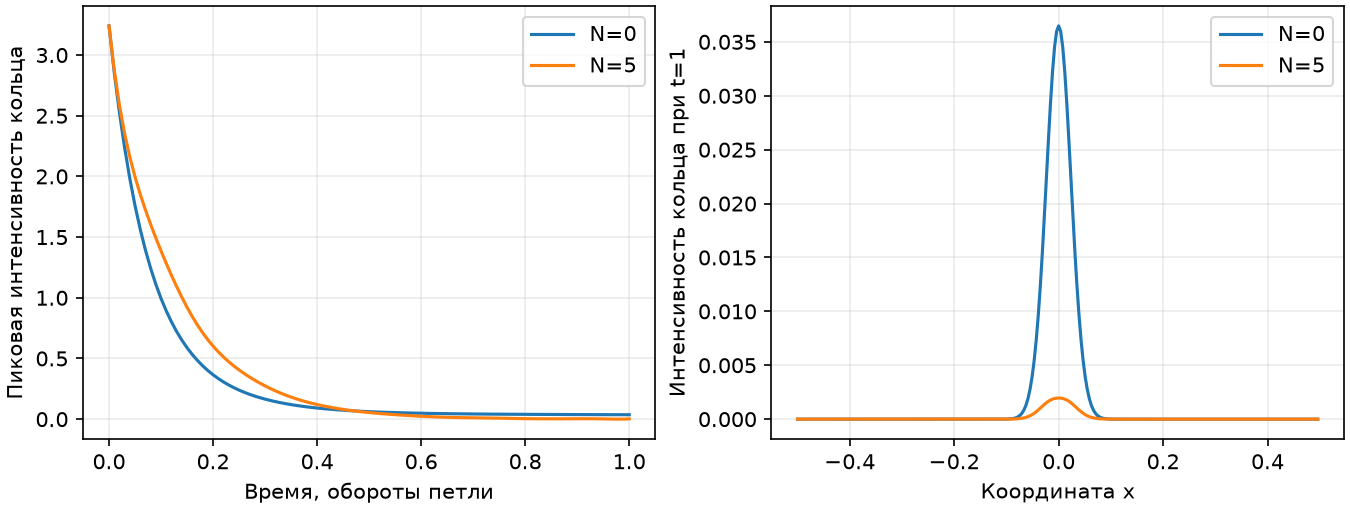

In [4]:
profiles = {}
print("  N   L2 кольца (128/256)   L2 петли (128/256)    пик при t=1")
for n in (0, 5):
    coarse = gaussian_run(n, 128, 0.001, 1.0, 0.01)
    fine = gaussian_run(n, 256, 0.001, 1.0, 0.01)
    profiles[n] = fine
    ea = relative_l2(coarse.ring.values[-1], fine.ring.values[-1, ::2])
    eb = relative_l2(coarse.loop[-1], fine.loop[-1, :, ::2])
    peak = np.max(abs(fine.ring.values[-1])**2)
    print(f"{n:3} {ea:20.4e} {eb:21.4e} {peak:15.6f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
for n, sol in profiles.items():
    intensity = abs(sol.ring.values)**2
    axes[0].plot(sol.ring.times, intensity.max(axis=1), label=f"N={n}")
    axes[1].plot(sol.ring.theta, intensity[-1], label=f"N={n}")
axes[0].set(xlabel="Время, обороты петли", ylabel="Пиковая интенсивность кольца")
axes[1].set(xlabel="Координата x", ylabel="Интенсивность кольца при t=1")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
path = results / "ring-pulse.png"
fig.savefig(path, dpi=150)
plt.close(fig)
display(Image(filename=str(path)))

## Выводы

При уменьшении шага вдвое ошибка комплексного поля уменьшается примерно в четыре раза как для точного решения, так и в расчете с одиннадцатью супермодами. При шаге 0.001 расхождение с DOP853 к моменту t=0.16 составляет 1.33e-6 для кольца и 2.29e-6 для полей петли в относительной норме L2.

Число супермод существенно влияет на переходный процесс. Для выбранного импульса при t=1 пиковая интенсивность кольца с N=5 примерно в 18.6 раза ниже, чем с N=0. При переходе от 128 к 256 узлам относительное расхождение комплексного поля кольца меньше 5e-8 в обоих вариантах. Этот расчет охватывает один оборот петли. Для сравнения со стационарным солитоном на рис. S3 нужна отдельная проверка профиля и частоты солитонной ветви.